# Train / validation / test + out-of-time split (step 14)

> **Development notebook.** Converted to `util/ml_split.py` (same code) and called from `script/mlpipeline.ipynb` and the Airflow model-training DAG. Change this notebook first, then re-convert.

Moved here from `script/mlpipeline.ipynb` so the split can run as its own Airflow task; the code is unchanged.

In [1]:
import os, sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import yaml
from pyspark.sql import functions as F
from sklearn.model_selection import train_test_split

# Project folder: /app inside the Docker container, otherwise the parent of this notebook's folder (notebooks/)
PROJECT_DIR = os.environ.get("PROJECT_DIR") or ("/app" if os.path.isdir("/app/data") else os.path.abspath(".."))
sys.path.insert(0, PROJECT_DIR)
from util import dataprocessing_bronze as bronze      # Spark session

GOLD_DIR = os.path.join(PROJECT_DIR, "datamart", "gold")
with open(os.path.join(PROJECT_DIR, "config", "data_contract.yaml"), encoding="utf-8") as f:
    CONTRACT = yaml.safe_load(f)
LABEL_DEF = CONTRACT["target"]["label_def"]
SCORING_COL = CONTRACT["scoring_timestamp"]["column"]

spark = bronze.get_spark("ml_split")

---

## Step 14 — Train / validation / test + out-of-time split

**Design** (agreed):

1. **Out-of-time (OOT) holdout, by time:** loans starting **2024-07 → 2025-01**. Used **once**, in step 31.
2. **Development period 2023-01 → 2024-06:** random split **stratified by label** into
   - **train 70%** — fitting, cross-validation, feature/target EDA (step 15),
   - **validation 15%** — early stopping, threshold choice, model comparison,
   - **test 15%** — in-time check of the frozen model (step 30/31).

**Why this design:** the model scores *future* applications, so the final estimate must come from later loans the model never saw (OOT); inside the development period a stratified random split gives balanced, stable train/validation/test sets. Comparing in-time test vs OOT shows how much performance drifts.

**Eligibility:** only loans with a **mature** label (contract). **Group rule:** a customer may appear in one partition only (here one loan per customer, so this holds by construction — asserted so a future repeat customer cannot slip through).

In [2]:
SPLIT_VERSION = "v1"
SPLIT_CONFIG = {
    "version": SPLIT_VERSION,
    "oot_start": "2024-07-01",                       # loans starting on/after this date -> OOT holdout
    "fractions": {"train": 0.70, "validation": 0.15, "test": 0.15},   # of the development period
    "seed": 42,
    "stratify_by": "label",
    "group_by": "Customer_ID",
    "label_def": LABEL_DEF,
    "eligibility": "maturity_status == 'mature'",
}
STRAT_TOLERANCE_PP = 1.0      # label rate of train/validation/test must be within 1 pp of the development rate
SIZE_TOLERANCE_PP = 1.0       # partition share within 1 pp of the configured fraction

SPLIT_DIR = os.path.join(GOLD_DIR, "split", SPLIT_VERSION)
CHART_DIR = os.path.join(GOLD_DIR, "_reports", "charts")
os.makedirs(SPLIT_DIR, exist_ok=True)
os.makedirs(CHART_DIR, exist_ok=True)

In [3]:
def load_population():
    # Eligible loans: mature label in the label store, present in the feature store
    fs = spark.read.parquet(os.path.join(GOLD_DIR, "feature_store", "v1")).select(
        "loan_id", "Customer_ID", SCORING_COL, F.col("_asof_clickstream").isNotNull().alias("has_clickstream_data"))
    ls = spark.read.parquet(os.path.join(GOLD_DIR, "label_store", LABEL_DEF)).select(
        "loan_id", "label", "maturity_status", "label_snapshot_date")
    pop = fs.join(ls, "loan_id", "inner").toPandas()
    pop[SCORING_COL] = pd.to_datetime(pop[SCORING_COL])
    pop["label_snapshot_date"] = pd.to_datetime(pop["label_snapshot_date"].astype(str))
    return pop[pop["maturity_status"] == "mature"].drop(columns="maturity_status").reset_index(drop=True)


def make_split(pop, cfg):
    oot = pop[SCORING_COL] >= pd.Timestamp(cfg["oot_start"])
    dev = pop[~oot]
    fr = cfg["fractions"]
    train, rest = train_test_split(dev, train_size=fr["train"], stratify=dev[cfg["stratify_by"]],
                                   random_state=cfg["seed"])
    val, test = train_test_split(rest, train_size=fr["validation"] / (fr["validation"] + fr["test"]),
                                 stratify=rest[cfg["stratify_by"]], random_state=cfg["seed"])
    part = pd.Series("oot", index=pop.index)
    part[train.index], part[val.index], part[test.index] = "train", "validation", "test"
    out = pop.assign(partition=part, split_version=cfg["version"], split_seed=cfg["seed"])
    return out[["loan_id", "Customer_ID", SCORING_COL, "label_snapshot_date", "label", "partition",
                "has_clickstream_data", "split_version", "split_seed"]]


population = load_population()
manifest = make_split(population, SPLIT_CONFIG)
manifest["created_ts"] = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
print(f"Eligible loans (mature labels): {len(population):,}")
manifest["partition"].value_counts().reindex(["train", "validation", "test", "oot"]).to_frame("loans")

Eligible loans (mature labels): 12,500


,loans
partition,
train,6281
validation,1346
test,1347
oot,3526


### Split summary

In [4]:
ORDER = ["train", "validation", "test", "oot"]
dev_rate = manifest.loc[manifest["partition"] != "oot", "label"].mean()
n_dev = (manifest["partition"] != "oot").sum()

summary = (manifest.groupby("partition")
           .agg(loans=("loan_id", "size"), positives=("label", "sum"), label_rate=("label", "mean"),
                first_loan_start=(SCORING_COL, "min"), last_loan_start=(SCORING_COL, "max"),
                cohorts=(SCORING_COL, "nunique"), with_clickstream=("has_clickstream_data", "mean"))
           .reindex(ORDER).reset_index())
summary["share_of_all_pct"] = summary["loans"] / len(manifest) * 100
summary["share_of_dev_pct"] = np.where(summary["partition"] != "oot", summary["loans"] / n_dev * 100, np.nan)
summary["label_rate_pct"] = summary["label_rate"] * 100
summary["with_clickstream_pct"] = summary["with_clickstream"] * 100
summary = summary.drop(columns=["label_rate", "with_clickstream"])
for c in ["first_loan_start", "last_loan_start"]:
    summary[c] = summary[c].dt.strftime("%Y-%m")
summary.to_csv(os.path.join(SPLIT_DIR, "split_summary.csv"), index=False)
print(f"Development-period label rate: {dev_rate * 100:.2f}%")
summary.style.hide(axis="index").format({"loans": "{:,}", "positives": "{:,}", "share_of_all_pct": "{:.1f}%",
                                         "share_of_dev_pct": "{:.1f}%", "label_rate_pct": "{:.2f}%",
                                         "with_clickstream_pct": "{:.0f}%"}, na_rep="—")

Development-period label rate: 28.87%


partition,loans,positives,first_loan_start,last_loan_start,cohorts,share_of_all_pct,share_of_dev_pct,label_rate_pct,with_clickstream_pct
train,"6,281","1,813",2023-01,2024-06,18,50.2%,70.0%,28.86%,100%
validation,"1,346",389,2023-01,2024-06,18,10.8%,15.0%,28.90%,100%
test,"1,347",389,2023-01,2024-06,18,10.8%,15.0%,28.88%,100%
oot,"3,526","1,011",2024-07,2025-01,7,28.2%,—,28.67%,0%


### Step 14 checks

| # | Check |
|---|---|
| 1 | Every eligible loan assigned to exactly one partition |
| 2 | **Zero customer overlap** between partitions (group rule) |
| 3 | **No temporal overlap:** every development loan starts before `oot_start`, every OOT loan on/after it |
| 4 | Stratification: train / validation / test label rates within 1 pp of the development rate |
| 5 | Partition sizes within 1 pp of the configured fractions |
| 6 | Reproducible: rebuilding with the same seed gives the identical assignment |
| 7 | Outcome window (reported): latest training outcome date vs first OOT scoring date |

In [5]:
checks = []
def check(name, status, observed, rule):
    checks.append(dict(check=name, status=status, observed=observed, rule=rule))

# 1
dup = manifest["loan_id"].duplicated().sum()
check("each eligible loan in exactly one partition", "PASS" if dup == 0 and len(manifest) == len(population) else "FAIL",
      f"{len(manifest):,} assigned, {dup} duplicates", "all eligible, no duplicates")

# 2
cust_parts = manifest.groupby("Customer_ID")["partition"].nunique()
overlap = int((cust_parts > 1).sum())
check("zero customer overlap between partitions", "PASS" if overlap == 0 else "FAIL",
      f"{overlap} customers in more than one partition", "0")

# 3
oot_start = pd.Timestamp(SPLIT_CONFIG["oot_start"])
dev_max = manifest.loc[manifest["partition"] != "oot", SCORING_COL].max()
oot_min = manifest.loc[manifest["partition"] == "oot", SCORING_COL].min()
check("no temporal overlap: development before OOT", "PASS" if dev_max < oot_start <= oot_min else "FAIL",
      f"last development loan {dev_max:%Y-%m}, first OOT loan {oot_min:%Y-%m}", f"dev < {oot_start:%Y-%m} <= OOT")

# 4
for p in ["train", "validation", "test"]:
    r = manifest.loc[manifest["partition"] == p, "label"].mean()
    gap = abs(r - dev_rate) * 100
    check(f"stratification: {p} label rate", "PASS" if gap <= STRAT_TOLERANCE_PP else "FAIL",
          f"{r * 100:.2f}% vs development {dev_rate * 100:.2f}% (gap {gap:.2f} pp)", f"<= {STRAT_TOLERANCE_PP} pp")

# 5
for p, frac in SPLIT_CONFIG["fractions"].items():
    share = (manifest["partition"] == p).sum() / n_dev
    check(f"size: {p}", "PASS" if abs(share - frac) * 100 <= SIZE_TOLERANCE_PP else "FAIL",
          f"{share * 100:.1f}% of development", f"{frac * 100:.0f}% ± {SIZE_TOLERANCE_PP} pp")

# 6
again = make_split(load_population(), SPLIT_CONFIG)
same = again.set_index("loan_id")["partition"].equals(manifest.set_index("loan_id")["partition"].loc[again["loan_id"]])
check("reproducible with the same seed", "PASS" if same else "FAIL", "identical assignment" if same else "differs", "identical")

# 7 (reported, not a failure): training outcomes observed after the first OOT scoring date
train_last_outcome = manifest.loc[manifest["partition"] == "train", "label_snapshot_date"].max()
overlap_months = (train_last_outcome.year - oot_start.year) * 12 + train_last_outcome.month - oot_start.month + 1
check("outcome window vs OOT start (reported)", "WARN" if train_last_outcome >= oot_start else "PASS",
      f"training outcomes observed up to {train_last_outcome:%Y-%m}; OOT scoring starts {oot_start:%Y-%m} "
      f"({max(overlap_months, 0)} months overlap)",
      "features are point-in-time (no feature leakage); a strict design would leave a 6-month gap")

split_checks = pd.DataFrame(checks)
split_checks.to_csv(os.path.join(SPLIT_DIR, "split_checks.csv"), index=False)
assert (split_checks["status"] != "FAIL").all(), split_checks[split_checks["status"] == "FAIL"]

STATUS_STYLE = {"PASS": ("✔ PASS", "#e3f4e3"), "WARN": ("▲ WARN", "#fdf0d2"), "FAIL": ("✖ FAIL", "#f8dede")}
view = split_checks.assign(status=split_checks["status"].map(lambda s: STATUS_STYLE[s][0]))
view.style.apply(lambda col: [f"background-color: {STATUS_STYLE[v.split()[-1]][1]}" for v in col],
                 subset=["status"]).hide(axis="index")

check,status,observed,rule
each eligible loan in exactly one partition,✔ PASS,"12,500 assigned, 0 duplicates","all eligible, no duplicates"
zero customer overlap between partitions,✔ PASS,0 customers in more than one partition,0
no temporal overlap: development before OOT,✔ PASS,"last development loan 2024-06, first OOT loan 2024-07",dev < 2024-07 <= OOT
stratification: train label rate,✔ PASS,28.86% vs development 28.87% (gap 0.01 pp),<= 1.0 pp
stratification: validation label rate,✔ PASS,28.90% vs development 28.87% (gap 0.03 pp),<= 1.0 pp
stratification: test label rate,✔ PASS,28.88% vs development 28.87% (gap 0.01 pp),<= 1.0 pp
size: train,✔ PASS,70.0% of development,70% ± 1.0 pp
size: validation,✔ PASS,15.0% of development,15% ± 1.0 pp
size: test,✔ PASS,15.0% of development,15% ± 1.0 pp
reproducible with the same seed,✔ PASS,identical assignment,identical


**About check 7 (WARN):** features never leak (they are as-of `loan_start_date`), but some *training* outcomes (MOB-6 dates up to 2024-12) are observed after the first OOT scoring date (2024-07). In a strict "deploy on 2024-07-01" simulation only loans starting by 2024-01 would have mature labels, i.e. a 6-month gap between development and OOT — which would drop ~2,500 training loans. The overlap is accepted and documented; it can make OOT slightly optimistic if risk changed during 2024-H2.

In [6]:
# Save the manifest and the configuration
manifest_out = manifest.copy()
for c in [SCORING_COL, "label_snapshot_date"]:
    manifest_out[c] = manifest_out[c].dt.strftime("%Y-%m-%d")
manifest_out.to_csv(os.path.join(SPLIT_DIR, "split_manifest.csv"), index=False)
with open(os.path.join(SPLIT_DIR, "split_config.yaml"), "w", encoding="utf-8") as f:
    yaml.safe_dump({**SPLIT_CONFIG, "eligible_loans": int(len(manifest)),
                    "development_label_rate": round(float(dev_rate), 6),
                    "created_ts": manifest["created_ts"].iloc[0]}, f, sort_keys=False)
print("Saved:", os.listdir(SPLIT_DIR))

Saved: ['split_checks.csv', 'split_config.yaml', 'split_manifest.csv', 'split_summary.csv']


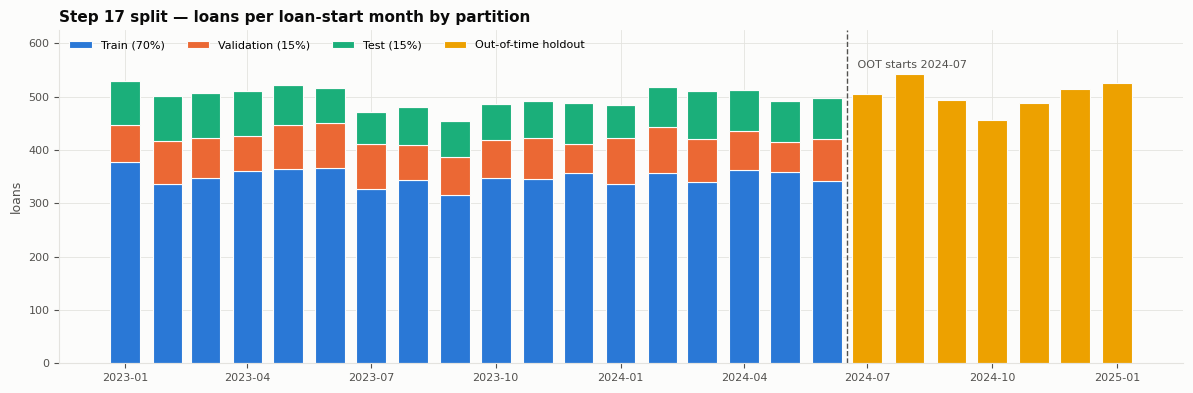

In [7]:
# Chart: loans per loan-start month by partition (train / validation / test inside development, OOT after)
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "xtick.color": INK_2, "ytick.color": INK_2,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
    "legend.fontsize": 8, "font.size": 9})

ct = manifest.groupby([SCORING_COL, "partition"]).size().unstack(fill_value=0).reindex(columns=ORDER, fill_value=0)
fig, ax = plt.subplots(figsize=(12, 4))
bottom = np.zeros(len(ct))
labels = {"train": "Train (70%)", "validation": "Validation (15%)", "test": "Test (15%)", "oot": "Out-of-time holdout"}
for color, p in zip(SERIES, ORDER):
    ax.bar(ct.index, ct[p], bottom=bottom, width=22, color=color, label=labels[p], edgecolor=SURFACE, linewidth=0.8)
    bottom += ct[p].values
ax.axvline(oot_start - pd.Timedelta(days=15), color=INK_2, linestyle="--", linewidth=1)
ax.text(oot_start - pd.Timedelta(days=10), ct.sum(axis=1).max() * 1.02, " OOT starts 2024-07", fontsize=8, color=INK_2)
ax.set_ylabel("loans")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="upper left", ncol=4)
ax.set_ylim(0, ct.sum(axis=1).max() * 1.15)
ax.set_title("Step 17 split — loans per loan-start month by partition")
fig.tight_layout()
fig.savefig(os.path.join(CHART_DIR, "17_split_by_cohort.png"), dpi=130, bbox_inches="tight")
plt.show()

### Step 14 summary

- **Frozen holdout:** OOT = loans starting 2024-07 → 2025-01, untouched until step 31. Also note it is the period **without clickstream** — the main model is the one without clickstream; a clickstream challenger needs its own late window inside development.
- **Development:** stratified 70 / 15 / 15 train / validation / test, seed 42, label rates within 1 pp.
- **Manifest** (`datamart/gold/split/v1/split_manifest.csv`): every loan's partition, with dates, label, seed and version — every later step reads its rows from here.
- **Next:** the Gold EDA (steps 15–17) on the frozen split.